# 01 · PhysioNet 2019 ingest and exploration — SepsisWatch Z

**Goal:** merge the 40,336 `.psv` files (one patient per file) into **a single table**, and understand the data before modeling.

**Input:** `~/shared/sepsis/data/raw/training_setA|B/*.psv` (downloaded with `data/download_physionet.sh`)
**Output:** `~/shared/sepsis/data/processed/sepsis_all.pkl` (pandas, `float32`)

Everything runs **inside the IBM LinuxONE (z17) VM**; no data leaves the machine.

## 1. Environment: confirm we are running on IBM Z

In [1]:
import os, platform, time, glob
from multiprocessing import Pool

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open("/proc/cpuinfo") as f:
    flags = next((line for line in f if line.startswith("features")), "").split()

print("Architecture                 :", platform.machine())
print("CPUs                         :", os.cpu_count())
print("On-chip AI accelerator (nnpa):", "nnpa" in flags)
print("SIMD vector units (vxe2)     :", "vxe2" in flags)

Architecture                 : s390x
CPUs                         : 3
On-chip AI accelerator (nnpa): True
SIMD vector units (vxe2)     : True


## 2. Paths and columns

Each file has **41 columns** in this order: 8 vital signs, 26 lab values, 6 patient fields and the `SepsisLabel` target.
The dataset has **no** patient ID or hospital column: the ID is in the **file name** and the hospital in the **folder**.

In [2]:
BASE = os.path.expanduser("~/shared/sepsis/data")
RAW = os.path.join(BASE, "raw")
OUT_DIR = os.path.join(BASE, "processed")
OUT_FILE = os.path.join(OUT_DIR, "sepsis_all.pkl")
FIG_DIR = "../docs/figures"   # pitch figures (inside the repo)

VITALS = ["HR", "O2Sat", "Temp", "SBP", "MAP", "DBP", "Resp", "EtCO2"]
LABS = ["BaseExcess", "HCO3", "FiO2", "pH", "PaCO2", "SaO2", "AST", "BUN",
        "Alkalinephos", "Calcium", "Chloride", "Creatinine", "Bilirubin_direct",
        "Glucose", "Lactate", "Magnesium", "Phosphate", "Potassium",
        "Bilirubin_total", "TroponinI", "Hct", "Hgb", "PTT", "WBC",
        "Fibrinogen", "Platelets"]
DEMOG = ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime", "ICULOS"]
COLUMNS = VITALS + LABS + DEMOG + ["SepsisLabel"]
print(len(COLUMNS), "columns")

41 columns


## 3. Read the 40,336 patients in parallel

`read_patient` reads **one** file and adds `patient_id`, `hospital` and `hour`.
`Pool(os.cpu_count())` reads them **in parallel on the 3 z17 CPUs**, in chunks of 500 files.
We use `float32` (half the memory of `float64`), which is also the format the NNPA accelerator works with.

In [3]:
def read_patient(path):
    df = pd.read_csv(path, sep="|", dtype=np.float32)
    if list(df.columns) != COLUMNS:
        raise ValueError(f"Unexpected columns in {path}")
    df.insert(0, "patient_id", os.path.basename(path)[:-4])        # p000001.psv -> p000001
    df.insert(1, "hospital", "A" if "training_setA" in path else "B")
    df.insert(2, "hour", np.arange(len(df), dtype=np.int16))
    return df

files = sorted(glob.glob(os.path.join(RAW, "training_set*", "*.psv")))
print(f"Files found: {len(files):,}")

t0 = time.time()
with Pool(os.cpu_count()) as pool:
    frames = pool.map(read_patient, files, chunksize=500)
t_read = time.time() - t0
print(f"Parallel read: {t_read:.1f} s on {platform.machine()} with {os.cpu_count()} CPUs")

Files found: 40,336
Parallel read: 45.3 s on s390x with 3 CPUs


## 4. Merge everything into one table and save it

In [4]:
t1 = time.time()
df = pd.concat(frames, ignore_index=True)
del frames
df["patient_id"] = df["patient_id"].astype("category")   # each ID stored once
df["hospital"] = df["hospital"].astype("category")
df["SepsisLabel"] = df["SepsisLabel"].astype(np.int8)

os.makedirs(OUT_DIR, exist_ok=True)
df.to_pickle(OUT_FILE)
t_total = t_read + (time.time() - t1)

print(f"Rows (patient-hours): {len(df):,} | Columns: {df.shape[1]}")
print(f"Memory in RAM: {df.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")
print(f"Saved to: {OUT_FILE} ({os.path.getsize(OUT_FILE) / 1024**2:,.0f} MB)")
print(f"Total ingest time: {t_total:.1f} s on {platform.machine()}")
df.head()

Rows (patient-hours): 1,552,210 | Columns: 44
Memory in RAM: 251 MB
Saved to: /home/ibm-user/shared/sepsis/data/processed/sepsis_all.pkl (249 MB)
Total ingest time: 60.2 s on s390x


,patient_id,hospital,hour,HR,O2Sat,Temp,SBP,MAP,DBP,Resp,...,WBC,Fibrinogen,Platelets,Age,Gender,Unit1,Unit2,HospAdmTime,ICULOS,SepsisLabel
0,p000001,A,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,83.139999,0.0,NaN,NaN,-0.03,1.0,0
1,p000001,A,1,97.0,95.0,NaN,98.0,75.330002,NaN,19.0,...,NaN,NaN,NaN,83.139999,0.0,NaN,NaN,-0.03,2.0,0
2,p000001,A,2,89.0,99.0,NaN,122.0,86.000000,NaN,22.0,...,NaN,NaN,NaN,83.139999,0.0,NaN,NaN,-0.03,3.0,0
3,p000001,A,3,90.0,95.0,NaN,NaN,NaN,NaN,30.0,...,NaN,NaN,NaN,83.139999,0.0,NaN,NaN,-0.03,4.0,0
4,p000001,A,4,103.0,88.5,NaN,122.0,91.330002,NaN,24.5,...,NaN,NaN,NaN,83.139999,0.0,NaN,NaN,-0.03,5.0,0


## 5. Summary by hospital (pitch numbers)

A patient "has sepsis" if their `SepsisLabel` is 1 at any point.

In [5]:
per_patient = df.groupby("patient_id", observed=True).agg(
    hospital=("hospital", "first"),
    hours=("hour", "size"),
    sepsis=("SepsisLabel", "max"),
    age=("Age", "first"),
    gender=("Gender", "first"),
)
summary = per_patient.groupby("hospital", observed=True).agg(
    patients=("sepsis", "size"),
    with_sepsis=("sepsis", "sum"),
    median_hours=("hours", "median"),
    median_age=("age", "median"),
)
summary["pct_sepsis"] = (100 * summary["with_sepsis"] / summary["patients"]).round(2)
summary.loc["Total"] = [summary["patients"].sum(), summary["with_sepsis"].sum(),
                        per_patient["hours"].median(), per_patient["age"].median(),
                        round(100 * per_patient["sepsis"].mean(), 2)]
summary

,patients,with_sepsis,median_hours,median_age,pct_sepsis
hospital,,,,,
A,20336.0,1790.0,39.0,64.669998,8.80
B,20000.0,1142.0,38.0,62.000000,5.71
Total,40336.0,2932.0,38.0,63.110001,7.27


## 6. How much data is missing?

In the ICU, **vital signs** are measured almost every hour, but **lab values** only a few times a day.
That is why most cells are `NaN`. This shapes how we build the features (carry the last measured value forward).

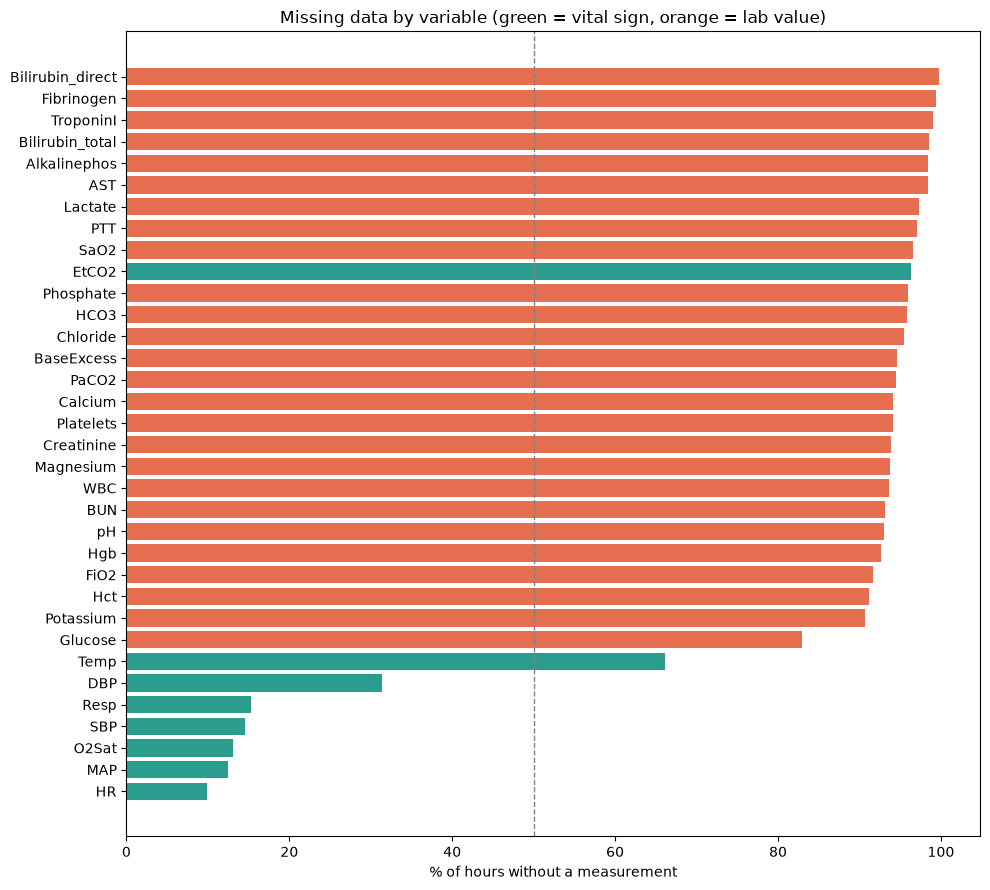

,HR,MAP,O2Sat,SBP,Resp,DBP,Temp,Glucose,Potassium,Hct,...,EtCO2,SaO2,PTT,Lactate,AST,Alkalinephos,Bilirubin_total,TroponinI,Fibrinogen,Bilirubin_direct
% missing,9.9,12.5,13.1,14.6,15.4,31.3,66.2,82.9,90.7,91.1,...,96.3,96.5,97.1,97.3,98.4,98.4,98.5,99.0,99.3,99.8


In [6]:
missing = (df[VITALS + LABS].isna().mean() * 100).sort_values()
colors = ["#2a9d8f" if c in VITALS else "#e76f51" for c in missing.index]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(missing.index, missing.values, color=colors)
ax.set_xlabel("% of hours without a measurement")
ax.set_title("Missing data by variable (green = vital sign, orange = lab value)")
ax.axvline(50, ls="--", c="grey", lw=1)
plt.tight_layout()
os.makedirs(FIG_DIR, exist_ok=True)
plt.savefig(f"{FIG_DIR}/01_missing_data.png", dpi=120)
plt.show()
missing.round(1).to_frame("% missing").T

## 7. One sepsis patient, hour by hour

`SepsisLabel` switches to **1 six hours before** the clinical onset of sepsis (Sepsis-3 definition).
We pick a sepsis patient with a long stay and good records, and look at how their vital signs change.

- **Red band:** hours with `SepsisLabel = 1` (what the model must detect).
- **Black line:** clinical sepsis onset (first labeled hour + 6).

Patient p000376 | hospital A | age 81 | 38 h in ICU | labeled from hour 28 | clinical onset ~ hour 34


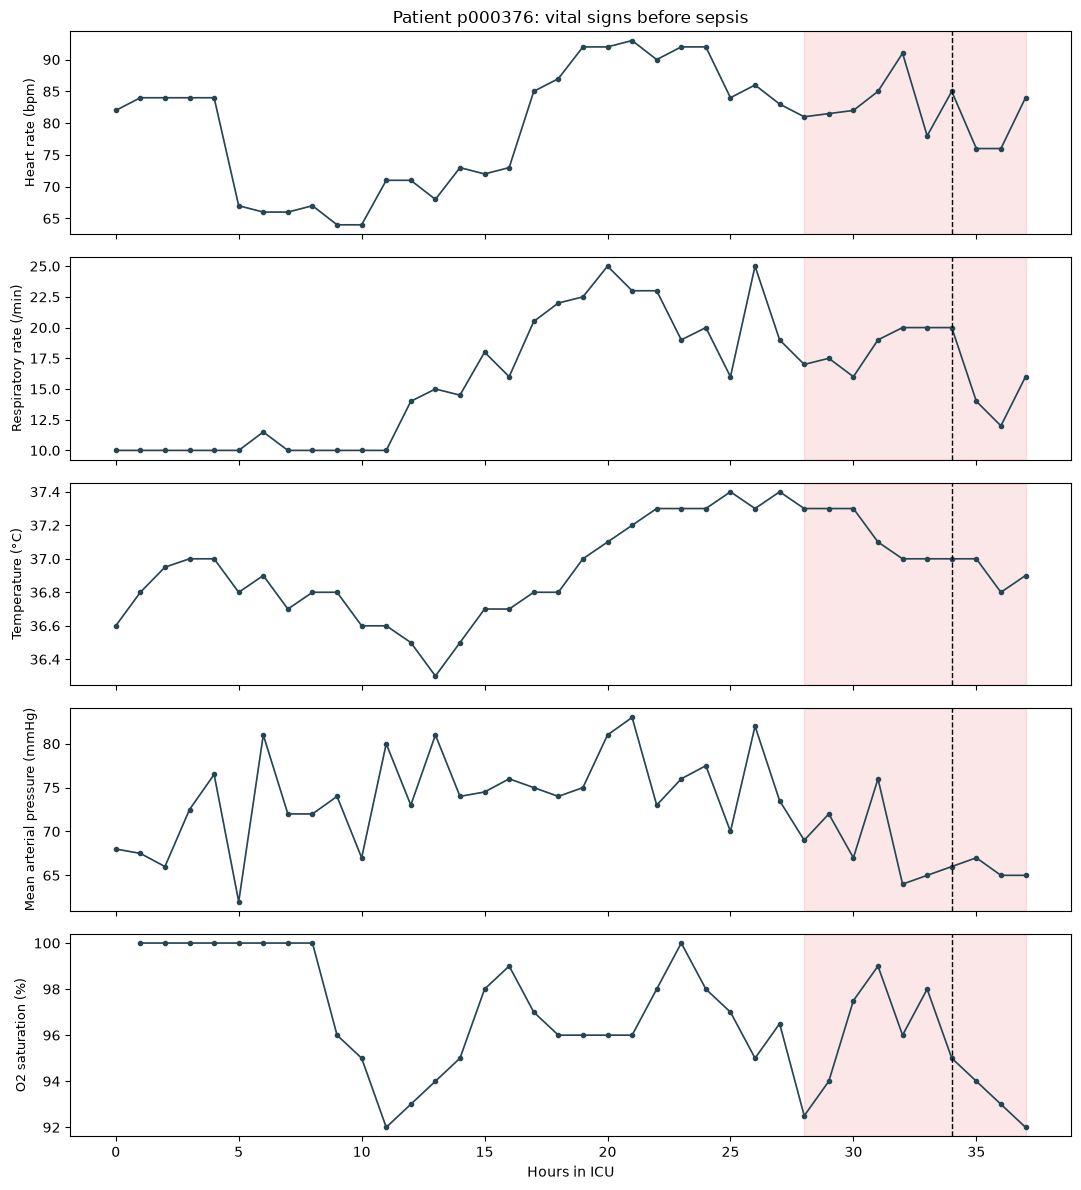

In [7]:
first_label = df[df["SepsisLabel"] == 1].groupby("patient_id", observed=True)["hour"].min()
cand = per_patient.loc[first_label.index].assign(first_label=first_label)
cand = cand[(cand["first_label"] >= 24) & (cand["hours"] >= cand["first_label"] + 10)]
hr_cov = df[df["patient_id"].isin(cand.index)].groupby("patient_id", observed=True)["HR"].count()
pid = (hr_cov.reindex(cand.index) / cand["hours"]).idxmax()

p = df[df["patient_id"] == pid].set_index("hour")
fl = int(cand.loc[pid, "first_label"])
onset = fl + 6
print(f"Patient {pid} | hospital {cand.loc[pid, 'hospital']} | age {cand.loc[pid, 'age']:.0f} | "
      f"{len(p)} h in ICU | labeled from hour {fl} | clinical onset ~ hour {onset}")

panels = [("HR", "Heart rate (bpm)"), ("Resp", "Respiratory rate (/min)"),
          ("Temp", "Temperature (°C)"), ("MAP", "Mean arterial pressure (mmHg)"),
          ("O2Sat", "O2 saturation (%)")]
fig, axes = plt.subplots(len(panels), 1, figsize=(11, 12), sharex=True)
for ax, (col, label) in zip(axes, panels):
    ax.plot(p.index, p[col].ffill(), c="lightgrey", lw=1)
    ax.plot(p.index, p[col], "o-", ms=3, lw=1.2, c="#264653")
    ax.axvspan(fl, p.index.max(), color="#e63946", alpha=0.12)
    ax.axvline(onset, c="black", ls="--", lw=1)
    ax.set_ylabel(label, fontsize=9)
axes[0].set_title(f"Patient {pid}: vital signs before sepsis")
axes[-1].set_xlabel("Hours in ICU")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/02_sepsis_patient.png", dpi=120)
plt.show()

## 8. Average pattern: what changes in the hours before sepsis?

We align **all** sepsis patients by the hours remaining until clinical onset, and compare with the average of patients **without** sepsis.
If the curves separate **before** onset, there is signal to predict early.

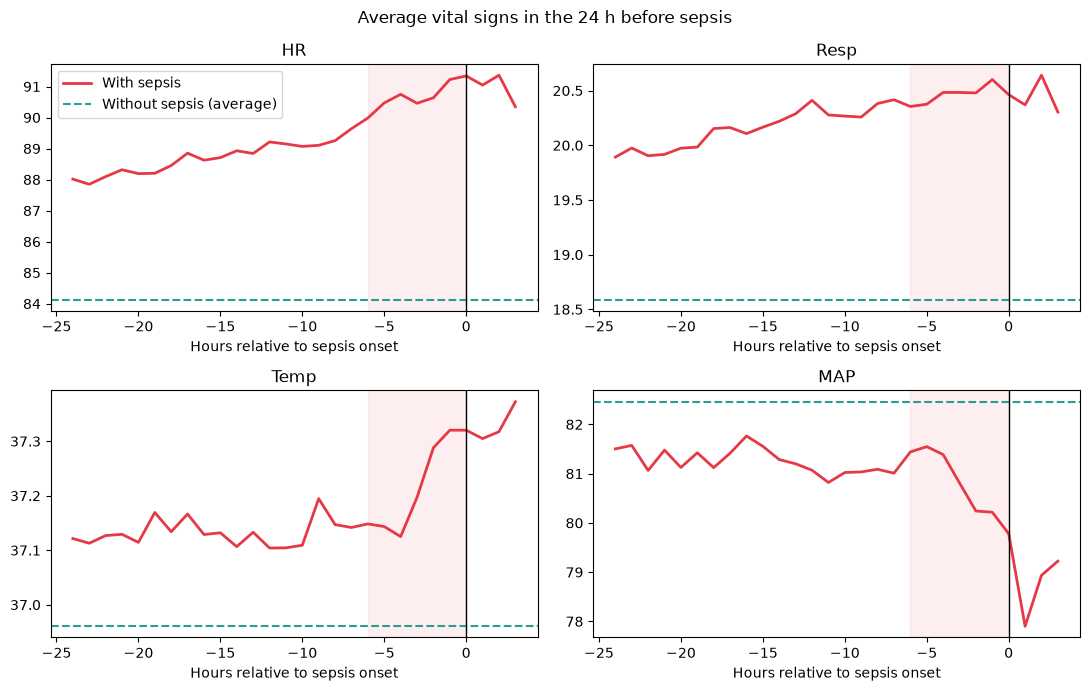

,HR,Resp,Temp,MAP
rel,,,,
-24.0,88.019997,19.889999,37.119999,81.500000
-12.0,89.209999,20.410000,37.099998,81.070000
-6.0,89.989998,20.350000,37.150002,81.440002
0.0,91.339996,20.459999,37.320000,79.779999


In [8]:
sep = df[df["patient_id"].isin(first_label.index)].copy()
sep["onset"] = sep["patient_id"].map(first_label + 6).astype(float)
sep["rel"] = sep["hour"] - sep["onset"]
window = sep[(sep["rel"] >= -24) & (sep["rel"] <= 6)]
trend = window.groupby("rel")[["HR", "Resp", "Temp", "MAP"]].mean()
baseline = df[~df["patient_id"].isin(first_label.index)][["HR", "Resp", "Temp", "MAP"]].mean()

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), trend.columns):
    ax.plot(trend.index, trend[col], c="#e63946", lw=2, label="With sepsis")
    ax.axhline(baseline[col], c="#2a9d8f", ls="--", label="Without sepsis (average)")
    ax.axvline(0, c="black", lw=1)
    ax.axvspan(-6, 0, color="#e63946", alpha=0.08)
    ax.set_title(col)
    ax.set_xlabel("Hours relative to sepsis onset")
axes[0, 0].legend()
fig.suptitle("Average vital signs in the 24 h before sepsis")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/03_pre_onset_trend.png", dpi=120)
plt.show()
trend.loc[[-24, -12, -6, 0]].round(2)

## 9. Exploration takeaways

- The data ends up in **a single table** ready for `02_features`, built on the z17 VM in seconds using the 3 CPUs in parallel.
- Sepsis is **rare** (a few % of patients): we must measure with **AUPRC, sensitivity and false alarms**, not accuracy.
- **Lab values are missing in most hours**: features must carry the last value forward and flag whether a measurement happened.
- Section 8 shows whether heart rate, respiratory rate and temperature trends **separate before onset**: that means there is signal for early alerts.
- Figures are saved in `docs/figures/` for the pitch.